In [ ]:
# BLOCK 1 -- Imports, global setup, figure/table styling

import os
import random
import copy
from dataclasses import dataclass, field
from typing import List, Dict, Tuple, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ---- reproducibility -------------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)


# Figure styling -------------------------------------------------------------

def set_origin_style():
    sns.set_theme(style="white", context="paper")
    plt.rcParams.update({
        "font.family": "Times New Roman",
        "font.size": 13,
        "axes.labelsize": 14,
        "axes.titlesize": 14,
        "axes.linewidth": 1.2,
        "xtick.direction": "in",
        "ytick.direction": "in",
        "xtick.major.width": 1.1,
        "ytick.major.width": 1.1,
        "xtick.major.size": 10,
        "ytick.major.size": 10,
        "legend.frameon": False,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.dpi": 1200,
    })

FIG_DIR = "figures"
TABLE_DIR = "tables"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)

def savefig(fig, name):
    path = os.path.join(FIG_DIR, f"{name}.png")
    fig.savefig(path, bbox_inches="tight")
    print("saved figure ->", path)

def save_table(df, name):
    path = os.path.join(TABLE_DIR, f"{name}.csv")
    df.to_csv(path, index=False)
    print("saved table  ->", path)

set_origin_style()
print("Setup complete. Figures ->", FIG_DIR, "| Tables ->", TABLE_DIR)

Setup complete. Figures -> figures | Tables -> tables


In [ ]:
# BLOCK 2 -- Extra imports, data, problem statement, self-check registry

import time, logging, warnings
from scipy import stats
from scipy.optimize import minimize, linear_sum_assignment
from sgp4.api import Satrec
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", message=".*findfont.*")
RNG = np.random.default_rng(SEED)
T_START = time.time()

DATA_DIR = "data"
F_TLE = os.path.join(DATA_DIR, "starlink_tle_2022-07-05_to_19.csv.gz")
assert os.path.exists(F_TLE), f"Missing data file: {F_TLE}"
PROVENANCE = pd.DataFrame([
    ("Starlink TLEs 2022-07-05..19", F_TLE, "space-track.org (18 SPCS), redistributed in github.com/self-driving-satellite-network/starlink-autonomous-driving"),
    ("NR numerology", "TS 38.211 cl. 4.1 / 5.3.1", "Tc = 1/(480e3*4096); kappa = 64; normal CP = 144*kappa*2^-mu*Tc"),
    ("PRACH CP lengths", "TS 38.211 Table 6.3.3.1-1/-2 (as implemented in srsRAN_Project lib/ran/prach/prach_preamble_information.cpp)",
     "format 0: 3168k; A1: 288k*2^-mu; A3: 864k*2^-mu; C2: 2048k*2^-mu"),
], columns=["input", "file_or_reference", "source"])
save_table(PROVENANCE, "T00_provenance"); print(PROVENANCE.to_string(index=False))

CHECKS, FINDINGS = [], []
def check(name, passed, detail=""):
    CHECKS.append({"check": name, "result": "PASS" if passed else "FAIL", "detail": detail})
    print(f"[{'PASS' if passed else 'FAIL'}] {name} :: {detail}")
def finding(fid, statement, evidence, supported):
    FINDINGS.append({"id": fid, "statement": statement, "evidence": evidence,
                     "verdict": "SUPPORTED" if supported else "NOT SUPPORTED"})
    print(f"<{fid}> {'SUPPORTED' if supported else 'NOT SUPPORTED'} :: {statement} :: {evidence}")

saved table  -> tables\T00_provenance.csv
                       input                                                                                            file_or_reference                                                                                                            source
Starlink TLEs 2022-07-05..19                                                                    data\starlink_tle_2022-07-05_to_19.csv.gz space-track.org (18 SPCS), redistributed in github.com/self-driving-satellite-network/starlink-autonomous-driving
               NR numerology                                                                                    TS 38.211 cl. 4.1 / 5.3.1                                                   Tc = 1/(480e3*4096); kappa = 64; normal CP = 144*kappa*2^-mu*Tc
            PRACH CP lengths TS 38.211 Table 6.3.3.1-1/-2 (as implemented in srsRAN_Project lib/ran/prach/prach_preamble_information.cpp)                                                  format 0: 3168k

In [ ]:
# BLOCK 3 -- Constants, NR numerology, geometry helpers (with self-checks)

MU, RE, F_WGS, WE, C_KM = 398600.4418, 6378.137, 1 / 298.257223563, 7.2921159e-5, 299792.458
MASK_DEG = 25.0
SEOUL_LAT, SEOUL_LON, SEOUL_H = 37.5665, 126.9780, 0.03
TC = 1.0 / (480e3 * 4096)
CP_US = {mu: 144 * 64 * 2 ** (-mu) * TC * 1e6 for mu in range(4)}
KAPPA = 64
PRACH_CP_US = {"format 0": 3168 * KAPPA * TC * 1e6, "A1 (15 kHz)": 288 * KAPPA * TC * 1e6,
               "A3 (15 kHz)": 864 * KAPPA * TC * 1e6, "C2 (15 kHz)": 2048 * KAPPA * TC * 1e6}
TOLS = {"data CP 15 kHz": CP_US[0], **PRACH_CP_US}
PRIMARY = "A3 (15 kHz)"; TOL = TOLS[PRIMARY]
check("CP(mu=0) = 4.6875 us", abs(CP_US[0] - 4.6875) < 1e-9, f"{CP_US[0]:.4f} us")
check("PRACH format-0 CP = 103.125 us", abs(PRACH_CP_US["format 0"] - 103.125) < 1e-9, f"{PRACH_CP_US['format 0']:.4f} us")
print(pd.DataFrame({"tolerance": list(TOLS), "us": list(TOLS.values())}).round(4).to_string(index=False))

def geodetic_to_ecef(lat_deg, lon_deg, h_km):
    lat, lon = np.radians(lat_deg), np.radians(lon_deg); e2 = F_WGS * (2 - F_WGS)
    N = RE / np.sqrt(1 - e2 * np.sin(lat) ** 2)
    return np.array([(N + h_km) * np.cos(lat) * np.cos(lon), (N + h_km) * np.cos(lat) * np.sin(lon),
                     (N * (1 - e2) + h_km) * np.sin(lat)])
UE = geodetic_to_ecef(SEOUL_LAT, SEOUL_LON, SEOUL_H)
UP = np.array([np.cos(np.radians(SEOUL_LAT)) * np.cos(np.radians(SEOUL_LON)),
               np.cos(np.radians(SEOUL_LAT)) * np.sin(np.radians(SEOUL_LON)), np.sin(np.radians(SEOUL_LAT))])

def gmst_rad(jd):
    T = (jd - 2451545.0) / 36525.0
    g = 67310.54841 + (876600 * 3600 + 8640184.812866) * T + 0.093104 * T**2 - 6.2e-6 * T**3
    return np.radians((g % 86400.0) / 240.0)

def teme_to_ecef_r(r, jd):
    """TEME -> ECEF position (polar motion neglected); jd shape must equal r[..., 0] shape."""
    assert np.shape(jd) == np.shape(r[..., 0])
    th = gmst_rad(jd); c, s = np.cos(th), np.sin(th)
    return np.stack([c * r[..., 0] + s * r[..., 1], -s * r[..., 0] + c * r[..., 1], r[..., 2]], -1)

def el_range(r_ecef):
    d = r_ecef - UE; rng = np.linalg.norm(d, axis=-1)
    return np.degrees(np.arcsin(np.clip((d @ UP) / rng, -1, 1))), rng

check("GMST at J2000.0", abs(np.degrees(gmst_rad(2451545.0)) - 280.46061837) < 1e-6, f"{np.degrees(gmst_rad(2451545.0)):.8f} deg")
e0, r0 = el_range(UE + 550 * UP)
check("Zenith geometry", abs(e0 - 90) < 1e-6 and abs(r0 - 550) < 1e-6, f"el={e0:.6f}, range={r0:.6f}")

[PASS] CP(mu=0) = 4.6875 us :: 4.6875 us
[PASS] PRACH format-0 CP = 103.125 us :: 103.1250 us
     tolerance       us
data CP 15 kHz   4.6875
      format 0 103.1250
   A1 (15 kHz)   9.3750
   A3 (15 kHz)  28.1250
   C2 (15 kHz)  66.6667
[PASS] GMST at J2000.0 :: 280.46061838 deg
[PASS] Zenith geometry :: el=90.000000, range=550.000000


In [ ]:
# BLOCK 4 -- Real TLEs: satellites, time split (train / validation / test), maneuvers, hazard

# Time split (no look-ahead anywhere):
#   TRAIN      [JD_BEGIN, JD_SPLIT)  : cost-model fitting data
#   VALIDATION [JD_VAL,   JD_SPLIT)  : design selection (cost model fitted on data before JD_VAL)
#   TEST       [JD_SPLIT, JD_END]    : used once, for the final report
tle = pd.read_csv(F_TLE)
tle["sat"] = [Satrec.twoline2rv(a, b) for a, b in zip(tle.TLE_LINE1, tle.TLE_LINE2)]
tle["jd"] = [s.jdsatepoch + s.jdsatepochF for s in tle.sat]
tle["a_km"] = [(MU / (s.no_kozai / 60.0) ** 2) ** (1 / 3) for s in tle.sat]
tle["alt_km"] = tle.a_km - RE
tle["inc"] = [np.degrees(s.inclo) for s in tle.sat]
tle = tle.sort_values(["NORAD_CAT_ID", "jd"]).drop_duplicates(["NORAD_CAT_ID", "jd"]).reset_index(drop=True)

JD_BEGIN = np.ceil(tle.jd.min() * 144) / 144
JD_SPLIT = 2459773.1666667                        # 2022-07-12 16:00 UTC
JD_VAL = JD_BEGIN + 3.5
JD_END = np.floor(tle.jd.max() * 144) / 144
first = tle[tle.jd < JD_VAL]
ps = first.groupby("NORAD_CAT_ID").agg(alt=("alt_km", "median"), sd=("alt_km", "std"), n=("jd", "size"))
op_first = ps[(ps.alt.between(530, 580)) & (ps.sd < 2.0) & (ps.n >= 5)].index
cover = tle.groupby("NORAD_CAT_ID").jd.agg(["min", "max"])
covered = cover[(cover["min"] < JD_BEGIN + 0.5) & (cover["max"] > JD_END - 0.5)].index
SAT_IDS = np.array(sorted(set(op_first) & set(covered)))
tle = tle[tle.NORAD_CAT_ID.isin(SAT_IDS)].reset_index(drop=True); NSAT = len(SAT_IDS)
print(f"satellites: {NSAT}; TLEs: {len(tle)}")
check("Split ordered: begin < val < split < end", JD_BEGIN < JD_VAL < JD_SPLIT < JD_END,
      f"{JD_BEGIN:.3f} < {JD_VAL:.3f} < {JD_SPLIT:.3f} < {JD_END:.3f}")

tle["da_m"] = tle.groupby("NORAD_CAT_ID").a_km.diff() * 1000
noise = tle.loc[tle.jd < JD_VAL, "da_m"].dropna()
SIG = 1.4826 * np.median(np.abs(noise - noise.median())); THR = max(100.0, 6 * SIG)
tle["man_step"] = (tle.da_m.abs() > THR).fillna(False)
print(f"TLE a-noise sigma {SIG:.1f} m -> maneuver threshold {THR:.0f} m (from data before JD_VAL)")

TLES, EPOCH, MANSTEP, MANCUM = [], [], [], []
for sid in SAT_IDS:
    g = tle[tle.NORAD_CAT_ID == sid]
    TLES.append(g.sat.to_list()); EPOCH.append(g.jd.to_numpy())
    MANSTEP.append(g.man_step.to_numpy()); MANCUM.append(np.cumsum(g.man_step.to_numpy().astype(int)))

def hazard_at(cutoff_jd, prior_days=7.0):
    """Per-satellite maneuver rate (per minute), Gamma-Poisson shrinkage, using epochs < cutoff only."""
    n = np.array([MANSTEP[i][(EPOCH[i] >= JD_BEGIN) & (EPOCH[i] < cutoff_jd)].sum() for i in range(NSAT)])
    days = cutoff_jd - JD_BEGIN; glob = n.sum() / (NSAT * days)
    return (n + glob * prior_days) / (days + prior_days) / 1440.0, glob / 1440.0

n_tr = np.array([MANSTEP[i][EPOCH[i] < JD_SPLIT].sum() for i in range(NSAT)])
n_te = np.array([MANSTEP[i][EPOCH[i] >= JD_SPLIT].sum() for i in range(NSAT)])
rho, pval = stats.spearmanr(n_tr, n_te)
T04 = pd.DataFrame({"quantity": ["satellites", "maneuvers train", "maneuvers test", "rate /sat/day (train)",
                                 "Spearman(train,test)", "p-value"],
                    "value": [NSAT, n_tr.sum(), n_te.sum(), n_tr.sum() / NSAT / (JD_SPLIT - JD_BEGIN), rho, pval]})
save_table(T04, "T04_data_and_hazard"); print(T04.to_string(index=False))
finding("P1", "Per-satellite maneuver propensity persists week to week", f"Spearman rho={rho:.3f}, p={pval:.1e}", rho > 0.1 and pval < 0.01)

satellites: 1087; TLEs: 36233
[PASS] Split ordered: begin < val < split < end :: 2459766.167 < 2459769.667 < 2459773.167 < 2459780.118
TLE a-noise sigma 25.6 m -> maneuver threshold 153 m (from data before JD_VAL)
saved table  -> tables\T04_data_and_hazard.csv
             quantity        value
           satellites 1.087000e+03
      maneuvers train 4.800000e+02
       maneuvers test 3.430000e+02
rate /sat/day (train) 6.308319e-02
 Spearman(train,test) 3.484436e-01
              p-value 2.199882e-32
<P1> SUPPORTED :: Per-satellite maneuver propensity persists week to week :: Spearman rho=0.348, p=2.2e-32


In [ ]:
# BLOCK 5 -- Truth and visibility over Seoul on a 1-min grid (train, validation, test)

TRUTH_MAX_H = 6.0
def ranges_from(tl, idx, jd):
    el = np.full(len(jd), -90.0); rg = np.full(len(jd), np.nan)
    for c in np.unique(idx):
        m = idx == c
        e, r, _ = tl[c].sgp4_array(jd[m], np.zeros(m.sum()))
        ee, rr = el_range(teme_to_ecef_r(r, jd[m])); ee[e != 0] = -90.0; el[m] = ee; rg[m] = rr
    return el, rg

def build_window(jd0, jd1):
    n = int(round((jd1 - jd0) * 1440)); jd = jd0 + np.arange(n) / 1440.0
    out = []
    for i in range(NSAT):
        ep, tl = EPOCH[i], TLES[i]
        pos = np.searchsorted(ep, jd)
        lo = np.clip(pos - 1, 0, len(ep) - 1); hi = np.clip(pos, 0, len(ep) - 1)
        near = np.where(np.abs(ep[hi] - jd) < np.abs(ep[lo] - jd), hi, lo)
        el, _ = ranges_from(tl, near, jd)
        vis = np.where(el >= MASK_DEG)[0]
        nxt = np.searchsorted(ep, jd[vis], side="right")
        okt = (nxt < len(ep)) & ((ep[np.clip(nxt, 0, len(ep) - 1)] - jd[vis]) * 24 <= TRUTH_MAX_H)
        ev = vis[okt]; tr_idx = nxt[okt]
        _, rgt = ranges_from(tl, tr_idx, jd[ev])
        out.append(dict(vis=vis, ev=ev, jd=jd[ev], truth=tr_idx, truth_jd=ep[tr_idx], rng_t=rgt,
                        latest=np.searchsorted(ep, jd[ev], side="right") - 1))
    return n, out

t0 = time.time()
NTR, WTR = build_window(JD_BEGIN, JD_SPLIT)
NVA, WVA = build_window(JD_VAL, JD_SPLIT)
NTE, WTE = build_window(JD_SPLIT, JD_END)
v_te = sum(len(w["vis"]) for w in WTE); e_te = sum(len(w["ev"]) for w in WTE)
print(f"windows in {time.time()-t0:.0f} s; test: {v_te:,} visible sat-min, {e_te:,} evaluable ({e_te/v_te:.1%})")
check("Mean satellites visible from Seoul plausible (5-40)", 5 <= v_te / NTE <= 40, f"{v_te/NTE:.1f}")
check("Evaluation subset >= 20% of visible minutes", e_te / v_te >= 0.2, f"{e_te/v_te:.1%}")
check("Truth never usable as a copy (truth epoch > minute)",
      all(np.all(w["truth_jd"] > w["jd"]) for w in WTE if len(w["ev"])), "")
JDTE = JD_SPLIT + np.arange(NTE) / 1440.0
samp = RNG.choice(NSAT, 150, replace=False); inter = union = 0
for i in samp:
    lat = np.searchsorted(EPOCH[i], JDTE - 1.0, side="right") - 1
    el_p, _ = ranges_from(TLES[i], np.clip(lat, 0, None), JDTE); el_p[lat < 0] = -90
    v_t = np.zeros(NTE, bool); v_t[WTE[i]["vis"]] = True; v_p = el_p >= MASK_DEG
    inter += (v_t & v_p).sum(); union += (v_t | v_p).sum()
check("Visibility predicted from 24-h-old data matches (Jaccard >= 0.95)", inter / union >= 0.95, f"Jaccard {inter/union:.4f}")

windows in 10 s; test: 73,339 visible sat-min, 27,862 evaluable (38.0%)
[PASS] Mean satellites visible from Seoul plausible (5-40) :: 7.3
[PASS] Evaluation subset >= 20% of visible minutes :: 38.0%
[PASS] Truth never usable as a copy (truth epoch > minute) :: 
[PASS] Visibility predicted from 24-h-old data matches (Jaccard >= 0.95) :: Jaccard 0.9877


In [ ]:
# BLOCK 6 -- Error tables and labelled samples (age, maneuver flag, |TA error|, truth time)

def error_tables(W):
    ERR = []
    for i in range(NSAT):
        w = W[i]; tl = TLES[i]; nv = len(w["ev"]); E = np.full((len(tl), nv), np.nan, np.float32)
        if nv:
            for c in range(len(tl)):
                e, r, _ = tl[c].sgp4_array(w["jd"], np.zeros(nv))
                _, rg = el_range(teme_to_ecef_r(r, w["jd"]))
                E[c] = np.abs(2 * (rg - w["rng_t"]) / C_KM * 1e6); E[c, e != 0] = np.nan
        ERR.append(E)
    return ERR
t0 = time.time(); ERR_TR = error_tables(WTR); ERR_VA = error_tables(WVA); ERR_TE = error_tables(WTE)
print(f"error tables in {time.time()-t0:.0f} s")

MAX_AGE_H = 168.0
def samples(W, ERR):
    A, M, E, T = [], [], [], []
    for i in range(NSAT):
        w = W[i]
        if not len(w["ev"]): continue
        age = (w["jd"][None, :] - EPOCH[i][:, None]) * 24.0
        ok = (age > 0) & (age <= MAX_AGE_H) & np.isfinite(ERR[i])
        man = (MANCUM[i][w["latest"]][None, :] - MANCUM[i][:, None]) > 0
        A.append(age[ok]); M.append(man[ok]); E.append(ERR[i][ok]); T.append(np.broadcast_to(w["truth_jd"], age.shape)[ok])
    return pd.DataFrame({"age_h": np.concatenate(A), "man": np.concatenate(M), "err_us": np.concatenate(E),
                         "truth_jd": np.concatenate(T)})
S_ALL = pd.concat([samples(WTR, ERR_TR), samples(WTE, ERR_TE)], ignore_index=True)
print(f"labelled samples: {len(S_ALL):,} (train part {int((S_ALL.truth_jd < JD_SPLIT).sum()):,})")
fresh = S_ALL[(S_ALL.truth_jd < JD_SPLIT) & (S_ALL.age_h < 2)]
print("violation of copies < 2 h old (train):", {k: round(float((fresh.err_us > v).mean()), 4) for k, v in TOLS.items()})
check("Primary tolerance not floor-limited (fresh-copy violation < 5%)", (fresh.err_us > TOL).mean() < 0.05,
      f"{(fresh.err_us > TOL).mean():.2%} at {PRIMARY}")

error tables in 3 s
labelled samples: 683,198 (train part 207,802)
violation of copies < 2 h old (train): {'data CP 15 kHz': 0.3252, 'format 0': 0.0, 'A1 (15 kHz)': 0.1629, 'A3 (15 kHz)': 0.0152, 'C2 (15 kHz)': 0.0013}
[PASS] Primary tolerance not floor-limited (fresh-copy violation < 5%) :: 1.52% at A3 (15 kHz)


saved table  -> tables\T07_cost_model_calibration.csv
 maneuver   age_bin     n  empirical  model  abs_gap                      model_fit
    False    (0, 6]  9482      0.013  0.025    0.012                     train only
    False   (6, 12] 11843      0.055  0.079    0.024                     train only
    False  (12, 24] 16662      0.092  0.171    0.079                     train only
    False  (24, 48] 37188      0.423  0.429    0.007                     train only
    False  (48, 96] 68552      0.697  0.628    0.070                     train only
    False (96, 168] 91942      0.859  0.688    0.172                     train only
     True  (12, 24]   713      0.215  0.253    0.038                     train only
     True  (24, 48]  2939      0.669  0.652    0.016                     train only
     True  (48, 96] 11375      0.859  0.811    0.049                     train only
     True (96, 168] 28169      0.932  0.884    0.049                     train only
    False    (0, 6]  9

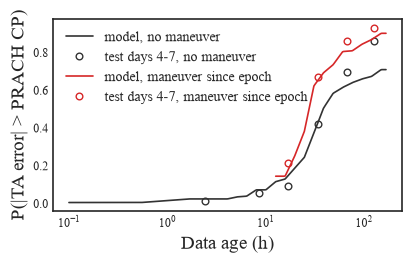

In [ ]:
# BLOCK 7 -- Cost model P(|TA err| > tol | age, maneuver): fit with a data cut-off, calibration

EDGES_H = np.geomspace(0.1, MAX_AGE_H, 34)
def pav(y, w):
    blocks = []
    for yi, wi in zip(y, w):
        blocks.append([yi, wi, 1])
        while len(blocks) > 1 and blocks[-2][0] > blocks[-1][0]:
            b = blocks.pop(); a = blocks[-1]
            a[0] = (a[0] * a[1] + b[0] * b[1]) / (a[1] + b[1]); a[1] += b[1]; a[2] += b[2]
    return np.concatenate([[v] * n for v, _, n in blocks])
def curve(age_h, y, min_n):
    b = np.digitize(age_h, EDGES_H); xs, ys, ws = [], [], []
    for k in range(1, len(EDGES_H)):
        m = b == k
        if m.sum() >= min_n:
            xs.append(np.sqrt(EDGES_H[k - 1] * EDGES_H[k])); ys.append(y[m].mean()); ws.append(m.sum())
    return np.log(np.array(xs)), pav(ys, ws)
def fit_cost(tol, cutoff_jd):
    d = S_ALL[S_ALL.truth_jd < cutoff_jd]; y = (d.err_us > tol).values.astype(float); m = d.man.values
    c0 = curve(d.age_h.values[~m], y[~m], 200); c1 = curve(d.age_h.values[m], y[m], 100)
    p0 = (lambda lx, ly: (lambda a: np.interp(np.log(np.clip(a / 60.0, 1e-3, None)), lx, ly)))(*c0)
    p1r = (lambda lx, ly: (lambda a: np.interp(np.log(np.clip(a / 60.0, 1e-3, None)), lx, ly)))(*c1)
    return p0, (lambda a: np.maximum(p1r(a), p0(a)))
def set_cost(tol, cutoff_jd):
    global P0, P1
    P0, P1 = fit_cost(tol, cutoff_jd)
def p_mix(age_min, haz_min):
    q = np.exp(-haz_min * age_min)
    return q * P0(age_min) + (1 - q) * P1(age_min)

BINS = [0, 6, 12, 24, 48, 96, 168]
def calib(p0, p1, d, tol):
    rows = []
    for man, pf in [(False, p0), (True, p1)]:
        x = d[d.man == man].copy(); x["bin"] = pd.cut(x.age_h, BINS)
        for b, g in x.groupby("bin", observed=True):
            if len(g) >= 200:
                rows.append({"maneuver": man, "age_bin": str(b), "n": len(g), "empirical": (g.err_us > tol).mean(),
                             "model": pf(g.age_h.values * 60).mean()})
    r = pd.DataFrame(rows); r["abs_gap"] = (r.empirical - r.model).abs(); return r
te = S_ALL[S_ALL.truth_jd >= JD_SPLIT + 3]                      # test days 4-7
static = calib(*fit_cost(TOL, JD_SPLIT), te, TOL).assign(model_fit="train only")
online = calib(*fit_cost(TOL, JD_SPLIT + 3), te, TOL).assign(model_fit="train + test days 1-3 (online)")
T07 = pd.concat([static, online]); save_table(T07, "T07_cost_model_calibration"); print(T07.round(3).to_string(index=False))
g_s = static[~static.maneuver].abs_gap.max(); g_o = online[~online.maneuver].abs_gap.max()
check("Cost model calibrated out-of-sample within 0.10 (static fit)", g_s <= 0.10, f"max gap {g_s:.3f}")
finding("C1", "Online refitting reduces calibration drift on later test days", f"max gap {g_s:.3f} -> {g_o:.3f}", g_o < g_s)
set_cost(TOL, JD_SPLIT); aa = np.array([6, 12, 24, 48, 96]) * 60.0
check("Maneuver never lowers risk", np.all(P1(aa) >= P0(aa)), " / ".join(f"{P0(a):.3f}->{P1(a):.3f}" for a in aa))

fig, ax = plt.subplots(figsize=(4.5, 2.5)); ag = np.geomspace(6, MAX_AGE_H * 60, 300)
d_tr = S_ALL[S_ALL.truth_jd < JD_SPLIT]
m_min_h = np.exp(curve(d_tr.age_h.values[d_tr.man.values], np.zeros(int(d_tr.man.sum())), 100)[0][0])   # first supported bin
for man, pf, col, lab in [(False, P0, "0.2", "no maneuver"), (True, P1, "tab:red", "maneuver since epoch")]:
    sel_ = ag / 60 >= (m_min_h if man else 0)                      # draw only where the fit has data
    ax.plot(ag[sel_] / 60, pf(ag[sel_]), color=col, label=f"model, {lab}")
    d = static[static.maneuver == man]
    mids = [np.sqrt(max(float(s.strip('(]').split(',')[0]), 1.0) * float(s.strip('(]').split(',')[1])) for s in d.age_bin]
    ax.plot(mids, d.empirical, "o", color=col, mfc="none", label=f"test days 4-7, {lab}")
ax.set_xscale("log"); ax.set_xlabel("Data age (h)"); ax.set_ylabel("P(|TA error| > PRACH CP)")
ax.legend(fontsize=10, loc="upper left"); savefig(fig, "F07_cost_model"); plt.show()

In [ ]:
# BLOCK 8 -- Scheduling policies on a generic window context

SLOT = 10
def make_ctx(W, ERR, jd0, nmin):
    ns = nmin // SLOT; slot_jd = jd0 + np.arange(ns) * SLOT / 1440.0
    VIS = np.zeros((NSAT, nmin + 24 * 60), bool)
    for i in range(NSAT): VIS[i, W[i]["vis"]] = True
    LATEST = np.stack([np.searchsorted(EPOCH[i], slot_jd, side="right") - 1 for i in range(NSAT)])
    EP = np.full((NSAT, max(len(e) for e in EPOCH)), np.nan)
    for i in range(NSAT): EP[i, :len(EPOCH[i])] = (EPOCH[i] - jd0) * 1440.0
    assert LATEST.min() >= 0
    return dict(W=W, ERR=ERR, jd0=jd0, nmin=nmin, ns=ns, slot_jd=slot_jd, VIS=VIS, LATEST=LATEST, EP=EP)
CTX_VA = make_ctx(WVA, ERR_VA, JD_VAL, NVA); CTX_TE = make_ctx(WTE, ERR_TE, JD_SPLIT, NTE)

def a0_at(cutoff_jd, n=20000):
    rng = np.random.default_rng(SEED); tt = JD_BEGIN + 0.5 + rng.uniform(0, cutoff_jd - JD_BEGIN - 0.5, n); ii = rng.integers(0, NSAT, n)
    return float(np.median([(t - EPOCH[i][np.searchsorted(EPOCH[i], t, side="right") - 1]) * 1440 for t, i in zip(tt, ii)]))

BASELINES = ["Round-robin", "Oldest-first", "Whittle-AoI", "Visibility-greedy", "Visibility x Age", "Visibility x Age-gain"]
A_MAX = 3000

def gains(rows_, age_min, age_new, haz, H):
    tau = np.arange(1, H + 1)
    return (p_mix(age_min[rows_, None] + tau, haz[rows_, None]) - p_mix(age_new[rows_, None] + tau, haz[rows_, None]))

def plan_mpc(rows_, G, K, H):
    """Exact receding-horizon assignment: satellites -> refresh slots (<= K per slot, one per satellite)."""
    R = max(H // SLOT, 1)
    suffix = np.cumsum(G[:, ::-1], 1)[:, ::-1]
    V = suffix[:, np.arange(R) * SLOT]
    Vrep = np.repeat(V, K, axis=1)
    r_idx, c_idx = linear_sum_assignment(-Vrep)
    now = (c_idx < K) & (Vrep[r_idx, c_idx] > 0)
    return rows_[r_idx[now]], V

def run_policy(ctx, name, K, tol, cfg=None):
    """cfg for proposed variants: dict(planner in {'mpc','greedy'}, lookahead bool, hazard bool, recal bool, H int)."""
    set_cost(tol, ctx["jd0"]); haz, haz_g = hazard_at(ctx["jd0"]); A0 = a0_at(ctx["jd0"])
    g = p_mix(A0 + SLOT * np.arange(A_MAX + 2), haz_g)
    W_TAB = (np.arange(A_MAX + 1) + 1) * g[1:] - np.cumsum(g[:-1])
    LATEST, EP, VIS = ctx["LATEST"], ctx["EP"], ctx["VIS"]
    copy_ = LATEST[:, 0].copy(); ar = np.arange(NSAT)
    COP = np.empty((NSAT, ctx["ns"]), np.int16); used = np.zeros(ctx["ns"], int)
    order = np.random.default_rng(SEED).permutation(NSAT); ptr = 0
    for s in range(ctx["ns"]):
        t = s * SLOT
        if cfg is not None and cfg["recal"] and s > 0 and t % 1440 == 0:
            set_cost(tol, ctx["slot_jd"][s]); haz, haz_g = hazard_at(ctx["slot_jd"][s])
        cand = LATEST[:, s] > copy_
        if name == "Refresh-all": pick = np.where(cand)[0]
        elif name == "Never-refresh": pick = np.array([], int)
        elif name == "Round-robin":
            pick = []; tries = 0
            while len(pick) < K and tries < NSAT:
                j = order[ptr % NSAT]; ptr += 1; tries += 1
                if cand[j]: pick.append(j)
            pick = np.array(pick, int)
        else:
            age_min = t - EP[ar, copy_]; age_new = t - EP[ar, LATEST[:, s]]
            H = cfg["H"] if cfg else 120
            up = VIS[:, t + 1:t + 1 + H]; nvis = up.sum(1)
            if name == "Oldest-first": sc = age_min.copy()
            elif name == "Whittle-AoI": sc = W_TAB[np.clip(((age_min - A0) // SLOT).astype(int), 0, A_MAX)]
            elif name == "Visibility-greedy": sc = nvis + 1e-6 * age_min
            elif name == "Visibility x Age": sc = nvis * age_min
            elif name == "Visibility x Age-gain": sc = nvis * (age_min - age_new)
            else:
                hz = haz if cfg["hazard"] else np.full(NSAT, haz_g)
                if cfg["lookahead"]:
                    rows_ = np.where(cand & (nvis > 0))[0]; M = up[rows_]
                else:
                    rows_ = np.where(cand)[0]; M = np.ones((len(rows_), H), bool)
                sc = np.full(NSAT, -1.0); sc[rows_] = 0.0
                if len(rows_):
                    G = gains(rows_, age_min, age_new, hz, H) * M
                    if cfg["planner"] == "mpc":
                        now, V = plan_mpc(rows_, G, K, H); sc[now] = 1.0 + V[np.searchsorted(rows_, now), 0]
                    else:
                        sc[rows_] = G.sum(1)
            sc = sc.astype(float); sc[~cand] = -np.inf
            k = min(K, int(cand.sum()))
            pick = np.argpartition(-sc, k - 1)[:k] if k > 0 else np.array([], int)
        copy_[pick] = LATEST[pick, s]; used[s] = len(pick); COP[:, s] = copy_
    return COP, used

WARMUP_MIN = 24 * 60
def evaluate(ctx, COP, tol):
    per_day = np.zeros((2, 10)); errs = []
    for i in range(NSAT):
        ev = ctx["W"][i]["ev"]; keep = ev >= WARMUP_MIN
        if not keep.any(): continue
        e = ctx["ERR"][i][COP[i, ev[keep] // SLOT], np.where(keep)[0]]
        ok = np.isfinite(e); d = (ev[keep] - WARMUP_MIN) // 1440
        np.add.at(per_day[0], d[ok], (e > tol)[ok]); np.add.at(per_day[1], d[ok], 1); errs.append(e[ok])
    return per_day[0].sum() / per_day[1].sum(), (per_day[0] / np.maximum(per_day[1], 1))[per_day[1] > 0], np.concatenate(errs)

set_cost(TOL, JD_SPLIT); A0_TR = a0_at(JD_SPLIT)
g = p_mix(A0_TR + SLOT * np.arange(A_MAX + 2), hazard_at(JD_SPLIT)[1])
check("Whittle index non-decreasing in age (indexability)", np.all(np.diff((np.arange(A_MAX + 1) + 1) * g[1:] - np.cumsum(g[:-1])) >= -1e-12), "")
print(f"median age of freshest available TLE: {A0_TR:.0f} min")

[PASS] Whittle index non-decreasing in age (indexability) :: 
median age of freshest available TLE: 334 min


In [ ]:
# BLOCK 9 -- Design selection on the VALIDATION window (test data untouched)

K_LIST = [1, 2, 3, 5, 8, 12]
import itertools
DESIGNS = [dict(planner=p, lookahead=True, hazard=h, recal=r, H=H)
           for p, h, r, H in itertools.product(["mpc", "greedy"], [True, False], [True, False], [60, 120, 240])]
t0 = time.time(); val = []
for K in K_LIST:
    for nm in BASELINES:
        COP, _ = run_policy(CTX_VA, nm, K, TOL); val.append({"design": nm, "K": K, "rate": evaluate(CTX_VA, COP, TOL)[0]})
    for d in DESIGNS:
        lab = f"{d['planner']}|haz={int(d['hazard'])}|recal={int(d['recal'])}|H={d['H']}"
        COP, _ = run_policy(CTX_VA, "Proposed", K, TOL, d); val.append({"design": lab, "K": K, "rate": evaluate(CTX_VA, COP, TOL)[0]})
VAL = pd.DataFrame(val); save_table(VAL, "T09_validation_all")
piv = VAL.pivot(index="design", columns="K", values="rate")
best_base = piv.loc[BASELINES].min(axis=0)
score_ = (piv.div(best_base, axis=1)).mean(axis=1).sort_values()                  # mean ratio to best baseline per K
print(f"validation runs in {time.time()-t0:.0f} s")
print((piv.loc[score_.index[:8]]).round(4)); print("\nbaselines:\n", piv.loc[BASELINES].round(4))
SEL_LABEL = [x for x in score_.index if x not in BASELINES][0]
SEL = [d for d in DESIGNS if f"{d['planner']}|haz={int(d['hazard'])}|recal={int(d['recal'])}|H={d['H']}" == SEL_LABEL][0]
print(f"\nSELECTED DESIGN (validation): {SEL}  | mean ratio to best baseline {score_[SEL_LABEL]:.3f}")
save_table(pd.DataFrame([{**SEL, "val_mean_ratio_to_best_baseline": score_[SEL_LABEL]}]), "T09b_selected_design")

saved table  -> tables\T09_validation_all.csv
validation runs in 171 s
K                            1       2       3       5       8       12
design                                                                 
mpc|haz=0|recal=0|H=120  0.6186  0.4693  0.3347  0.1696  0.0574  0.0378
mpc|haz=0|recal=0|H=240  0.6234  0.4711  0.3355  0.1700  0.0572  0.0381
mpc|haz=1|recal=0|H=120  0.6140  0.4747  0.3393  0.1720  0.0581  0.0380
mpc|haz=1|recal=0|H=240  0.6144  0.4713  0.3471  0.1718  0.0589  0.0379
mpc|haz=1|recal=1|H=120  0.6181  0.4719  0.3501  0.1722  0.0586  0.0383
mpc|haz=0|recal=1|H=120  0.6216  0.4760  0.3425  0.1747  0.0585  0.0382
mpc|haz=1|recal=1|H=240  0.6171  0.4745  0.3520  0.1768  0.0593  0.0380
mpc|haz=0|recal=1|H=240  0.6260  0.4737  0.3468  0.1770  0.0604  0.0380

baselines:
 K                          1       2       3       5       8       12
design                                                               
Round-robin            0.6527  0.5474  0.4443  0.2892  0

test runs in 117 s; refresh-all needs 18.0 refreshes/slot
[PASS] Budget respected by all test runs :: 
[PASS] All policies within [refresh-all - 0.002, never-refresh] :: bounds 0.0333 / 0.8309
saved table  -> tables\T10_test_violation_vs_K.csv
K                          1       2       3       5       8       12
policy                                                               
Round-robin            0.6822  0.5172  0.4142  0.2633  0.1324  0.0798
Oldest-first           0.6700  0.5346  0.4290  0.2683  0.1117  0.0767
Whittle-AoI            0.6741  0.5339  0.4210  0.2706  0.1109  0.0766
Visibility-greedy      0.6594  0.5189  0.4038  0.2357  0.1180  0.0492
Visibility x Age       0.6236  0.4664  0.3385  0.1750  0.0726  0.0416
Visibility x Age-gain  0.6290  0.4532  0.3318  0.1705  0.0714  0.0412
Proposed               0.6375  0.4621  0.3333  0.1648  0.0629  0.0368
saved table  -> tables\T10b_test_improvement.csv
 K best_baseline_on_test  baseline  proposed  relative_reduction_%  gap_to_re

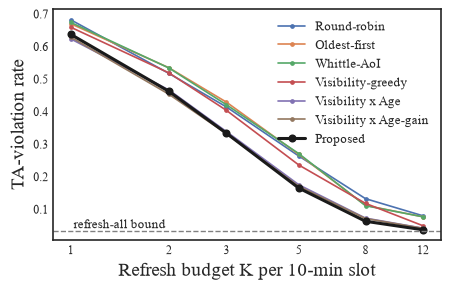

In [ ]:
# BLOCK 10 -- TEST: selected design vs baselines and bounds (test used once here)

ABL = {"Proposed": SEL,
       "w/o MPC (greedy index)": {**SEL, "planner": "greedy" if SEL["planner"] == "mpc" else "mpc"},
       "w/o look-ahead": {**SEL, "lookahead": False},
       "hazard flipped": {**SEL, "hazard": not SEL["hazard"]},
       "recalibration flipped": {**SEL, "recal": not SEL["recal"]}}
RES, DAY, ERRS = {}, {}, {}; t0 = time.time()
for nm in ["Never-refresh", "Refresh-all"]:
    COP, used = run_policy(CTX_TE, nm, 0, TOL); RES[(nm, 0)], DAY[(nm, 0)], ERRS[(nm, 0)] = evaluate(CTX_TE, COP, TOL)
    if nm == "Refresh-all": N_ALL = used.mean()
over = []
for K in K_LIST:
    for nm in BASELINES:
        COP, used = run_policy(CTX_TE, nm, K, TOL); RES[(nm, K)], DAY[(nm, K)], ERRS[(nm, K)] = evaluate(CTX_TE, COP, TOL); over.append(used.max() > K)
    for nm, cfg in ABL.items():
        COP, used = run_policy(CTX_TE, "Proposed", K, TOL, cfg); RES[(nm, K)], DAY[(nm, K)], ERRS[(nm, K)] = evaluate(CTX_TE, COP, TOL); over.append(used.max() > K)
print(f"test runs in {time.time()-t0:.0f} s; refresh-all needs {N_ALL:.1f} refreshes/slot")
check("Budget respected by all test runs", not any(over), "")
lo, hi = RES[("Refresh-all", 0)], RES[("Never-refresh", 0)]
bad = [(nm, K) for (nm, K), v in RES.items() if K > 0 and not (lo - 0.002 <= v <= hi)]
check("All policies within [refresh-all - 0.002, never-refresh]", not bad, f"bounds {lo:.4f} / {hi:.4f}")

T10 = pd.DataFrame([{"policy": nm, "K": K, "violation_rate": RES[(nm, K)]} for nm in BASELINES + ["Proposed"] for K in K_LIST])
save_table(T10, "T10_test_violation_vs_K")
print(T10.pivot(index="policy", columns="K", values="violation_rate").loc[BASELINES + ["Proposed"]].round(4))
imp = []
for K in K_LIST:
    bb = min(BASELINES, key=lambda p: RES[(p, K)])
    imp.append({"K": K, "best_baseline_on_test": bb, "baseline": RES[(bb, K)], "proposed": RES[("Proposed", K)],
                "relative_reduction_%": 100 * (1 - RES[("Proposed", K)] / RES[(bb, K)]),
                "gap_to_refresh_all_closed_%": 100 * (RES[(bb, K)] - RES[("Proposed", K)]) / (RES[(bb, K)] - lo)})
T10b = pd.DataFrame(imp); save_table(T10b, "T10b_test_improvement"); print(T10b.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(5, 3))
for nm in BASELINES + ["Proposed"]:
    kw = dict(color="k", lw=2.2, marker="o") if nm == "Proposed" else dict(marker=".", lw=1.2)
    ax.plot(K_LIST, [RES[(nm, K)] for K in K_LIST], label=nm, **kw)
ax.axhline(lo, color="0.5", ls="--", lw=1); ax.text(K_LIST[0], lo, " refresh-all bound", ha="left", va="bottom", fontsize=9)
ax.set_xscale("log"); ax.set_xticks(K_LIST); ax.set_xticklabels(K_LIST)
ax.set_xlabel("Refresh budget K per 10-min slot"); ax.set_ylabel("TA-violation rate")
ax.legend(fontsize=9.5, ncol=1, loc="upper right"); savefig(fig, "F10_test_violation_vs_K"); plt.show()

saved table  -> tables\T11_significance.csv
 K                    vs  days  mean_daily_gain  CI95_low  CI95_high  days_better  wilcoxon_p
 1      Visibility x Age     6         -0.01539  -0.03293   -0.00135            1     0.96875
 2 Visibility x Age-gain     6         -0.00848  -0.03128    0.01534            3     0.78125
 3 Visibility x Age-gain     6         -0.00020  -0.01827    0.01612            3     0.57812
 5 Visibility x Age-gain     6          0.00599  -0.00169    0.01430            4     0.15625
 8 Visibility x Age-gain     6          0.00839   0.00441    0.01265            6     0.01562
12 Visibility x Age-gain     6          0.00430   0.00083    0.00902            5     0.03125
<A1> NOT SUPPORTED :: Proposed beats the strongest baseline on test (Visibility x Age) at K=1 :: rel. reduction -2.2%; daily gain -0.0154 [95% CI -0.0329,-0.0014], better on 1/6 days
<A2> NOT SUPPORTED :: Proposed beats the strongest baseline on test (Visibility x Age-gain) at K=2 :: rel. reductio

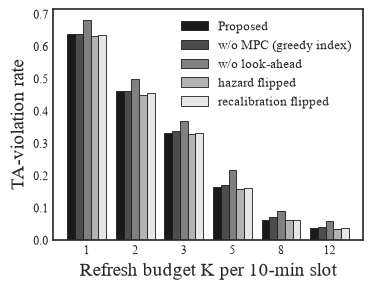

In [ ]:
# BLOCK 11 -- Significance (paired over test days) and ablations

rows = []
for K in K_LIST:
    bb = T10b.set_index("K").loc[K, "best_baseline_on_test"]
    d = DAY[(bb, K)] - DAY[("Proposed", K)]
    bs = np.array([RNG.choice(d, len(d)).mean() for _ in range(5000)])
    w = stats.wilcoxon(d, alternative="greater") if np.any(d != 0) else None
    rows.append({"K": K, "vs": bb, "days": len(d), "mean_daily_gain": d.mean(), "CI95_low": np.percentile(bs, 2.5),
                 "CI95_high": np.percentile(bs, 97.5), "days_better": int((d > 0).sum()), "wilcoxon_p": w.pvalue if w else np.nan})
T11 = pd.DataFrame(rows); save_table(T11, "T11_significance"); print(T11.round(5).to_string(index=False))
for _, r in T11.iterrows():
    finding(f"A{int(r.K)}", f"Proposed beats the strongest baseline on test ({r.vs}) at K={int(r.K)}",
            f"rel. reduction {T10b.set_index('K').loc[r.K,'relative_reduction_%']:.1f}%; daily gain {r.mean_daily_gain:.4f} "
            f"[95% CI {r.CI95_low:.4f},{r.CI95_high:.4f}], better on {r.days_better}/{r.days} days",
            r.CI95_low > 0)

abl = pd.DataFrame([{"K": K, **{nm: RES[(nm, K)] for nm in ABL}} for K in K_LIST]); save_table(abl, "T11b_ablation")
print(abl.round(4).to_string(index=False))
fig, ax = plt.subplots(figsize=(4, 3)); x = np.arange(len(K_LIST)); wdt = 0.16
for j, nm in enumerate(ABL):
    ax.bar(x + (j - 2) * wdt, abl[nm], wdt, label=nm, color=str(0.1 + 0.2 * j), edgecolor="k", lw=0.6)
ax.set_xticks(x); ax.set_xticklabels(K_LIST); ax.set_xlabel("Refresh budget K per 10-min slot")
ax.set_ylabel("TA-violation rate"); ax.legend(fontsize=9.5, loc="upper right"); savefig(fig, "F11_ablation"); plt.show()

saved table  -> tables\T12_tolerance_sensitivity.csv
     tolerance   tol_us  Refresh-all  Round-robin  Oldest-first  Whittle-AoI  Visibility-greedy  Visibility x Age  Visibility x Age-gain  Proposed         best_baseline  relative_reduction_%
data CP 15 kHz   4.6875       0.4753       0.7215        0.7186       0.7188             0.6575            0.6444                 0.6423    0.6380 Visibility x Age-gain                0.6701
      format 0 103.1250       0.0008       0.0433        0.0435       0.0432             0.0614            0.0171                 0.0166    0.0108 Visibility x Age-gain               34.7500
   A1 (15 kHz)   9.3750       0.2430       0.5552        0.5560       0.5581             0.4923            0.4560                 0.4499    0.4481 Visibility x Age-gain                0.4048
   A3 (15 kHz)  28.1250       0.0333       0.2633        0.2683       0.2706             0.2357            0.1750                 0.1705    0.1648 Visibility x Age-gain               

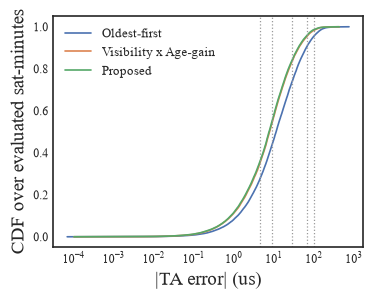

In [ ]:
# BLOCK 12 -- Sensitivity to the timing tolerance (cost model refitted per tolerance)

K_S = 5; rows = []
for tn, tv in TOLS.items():
    r = {"tolerance": tn, "tol_us": tv}
    COP, _ = run_policy(CTX_TE, "Refresh-all", 0, tv); r["Refresh-all"] = evaluate(CTX_TE, COP, tv)[0]
    for nm in BASELINES:
        COP, _ = run_policy(CTX_TE, nm, K_S, tv); r[nm] = evaluate(CTX_TE, COP, tv)[0]
    COP, _ = run_policy(CTX_TE, "Proposed", K_S, tv, SEL); r["Proposed"] = evaluate(CTX_TE, COP, tv)[0]
    r["best_baseline"] = min(BASELINES, key=lambda p: r[p]); r["relative_reduction_%"] = 100 * (1 - r["Proposed"] / r[r["best_baseline"]])
    rows.append(r)
T12 = pd.DataFrame(rows); save_table(T12, "T12_tolerance_sensitivity"); print(T12.round(4).to_string(index=False))
finding("S1", f"Proposed is best at K={K_S} for every timing tolerance",
        "; ".join(f"{r.tolerance}: {r['relative_reduction_%']:.1f}%" for _, r in T12.iterrows()), bool((T12["relative_reduction_%"] > 0).all()))

fig, ax = plt.subplots(figsize=(4, 3))
for nm in ["Oldest-first", "Visibility x Age-gain", "Proposed"]:
    e = np.sort(ERRS[(nm, K_S)]); ax.plot(e, np.linspace(0, 1, len(e)), label=nm)
for tv in TOLS.values(): ax.axvline(tv, color="0.6", ls=":", lw=0.9)
ax.set_xscale("log"); ax.set_xlabel("|TA error| (us)"); ax.set_ylabel("CDF over evaluated sat-minutes")
ax.legend(fontsize=9.5, loc="upper left"); savefig(fig, "F12_error_cdf"); plt.show()